# **AE Complex 1: autoencoder y morphing facial**

## **0. Introducción y objetivo**

En este notebook iniciamos el estudio de autoencoders aplicado a la generación de transiciones entre caras. Trabajaremos con imágenes RGB de caras de CelebA preprocesadas a `64x64` y construiremos un modelo que aprenda a comprimir cada imagen en una representación latente y a reconstruirla a partir de ella.

Un **autoencoder** es una red neuronal formada por dos partes: el **encoder**, que transforma una entrada de alta dimensión en un vector latente más compacto, y el **decoder**, que intenta recuperar la entrada original desde ese vector. Al entrenarlo con la propia imagen como objetivo, aprendemos una representación que concentra la información visual más relevante para la reconstrucción.

Después usaremos esa representación latente para hacer *morphing*: en lugar de mezclar píxeles directamente, interpolaremos entre los vectores de dos caras y decodificaremos los puntos intermedios. Así podremos observar si el espacio latente aprendido ofrece una transición visual suave y semánticamente coherente.

Este notebook es **determinista en la medida permitida por el entorno**: fijamos las semillas de NumPy y TensorFlow, usamos particiones ya guardadas y seleccionamos siempre los mismos ejemplos. Por defecto `TRAIN_MODEL = False`, de modo que podemos reproducir las visualizaciones y métricas cargando los modelos y el historial ya calculados desde `autoencoders/checkpoints/`. Si queremos repetir el entrenamiento, cambiamos esa parámetro a `True`.

El recorrido será: cargar los datos, definir la arquitectura, justificar la función de pérdida, entrenar o cargar el modelo, evaluar reconstrucciones en `test`, medir la calidad con FID y terminar generando una secuencia y un GIF de morphing.

---

## **1. Configuración e imports**

Importamos las bibliotecas de visualización, tratamiento de imágenes, TensorFlow y TorchMetrics. Las rutas se resuelven desde `autoencoders/`, donde está este notebook. Conservamos `attrs.npy` para análisis posteriores, aunque el entrenamiento del autoencoder utiliza las imágenes y sus identificadores.

In [2]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

In [ ]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
LATENT_DIM = 128
BATCH_SIZE = 128
EPOCHS = 60
FID_BATCH_SIZE = 32

TRAIN_MODEL = False
NOTEBOOK_NAME = "ae_complex1"

PROCESSED_DIR = Path("../data/processed")

# Verificamos que las tres particiones contienen los archivos esperados.
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

AE_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}.keras"
ENCODER_PATH = CHECKPOINT_DIR / f"encoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
DECODER_PATH = CHECKPOINT_DIR / f"decoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"

np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")

Datos localizados correctamente en: /Users/dani22/Desktop/ProyectoCD/morphing/data/processed


In [ ]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test`**

No volvemos a crear un *split*: respetamos las particiones guardadas en `data/processed` para que las comparaciones entre experimentos sean justas. Convertimos las imágenes de `uint8 [0, 255]` a `float32 [0, 1]`, porque la salida del decoder usa una activación sigmoide. El autoencoder aprende la identidad, por lo que la entrada y el objetivo de cada ejemplo son la misma imagen.

In [ ]:
def load_split(name):
    # Cargamos cada partición sin modificar el split ya preparado.
    split_dir = PROCESSED_DIR / name
    
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, CHANNELS):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    
    # Normalizamos para que coincida con la salida sigmoide del decoder.
    return x.astype("float32") / 255.0, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")


train: (60000, 64, 64, 3), val: (5000, 64, 64, 3), test: (10000, 64, 64, 3)
Rango train: [0.000, 1.000]


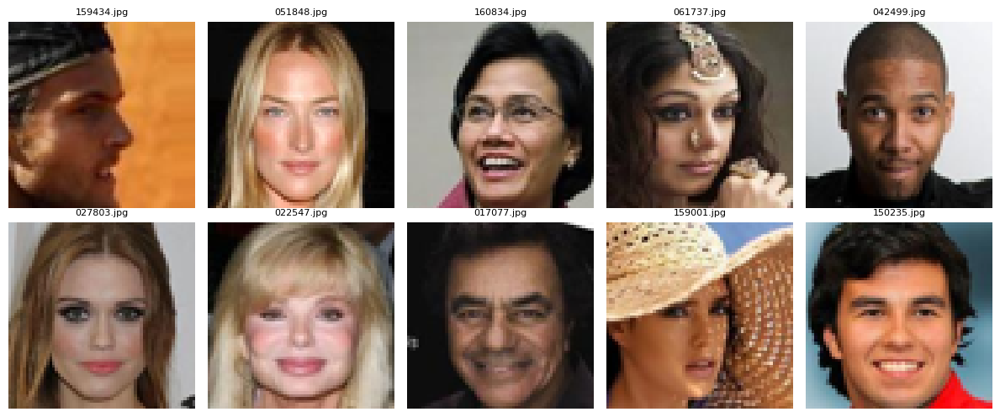

In [ ]:
# Ejemplos de algunas imágenes

def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))


---

## **3. Encoder, decoder y autoencoder**

El **encoder** comprime cada cara RGB de `64x64x3` en un vector latente de `128` valores. El **decoder** recorre el camino inverso y devuelve tres canales RGB en `[0, 1]`. Elegimos una arquitectura convolucional porque las convoluciones aprovechan la localidad espacial de los rostros, mientras que las reducciones sucesivas de resolución permiten aumentar el número de filtros y aprender rasgos cada vez más abstractos.

Usamos bloques `Conv2D` con *stride* 2 para reducir gradualmente `64x64` hasta `4x4`, seguidos de `BatchNormalization` y `LeakyReLU` para estabilizar y hacer más fluido el entrenamiento. También podríamos hacerlo con `MaxPooling`, aunque hemos preferido que sea la convolución la que realice la reducción de resolución. En estos notebooks esta decisión de diseño no ha sido demostrada por claridad, aunque ha sido probada en nuestros experimentos privados. 

En el decoder partimos del vector latente, recuperamos un mapa `4x4x256` y usamos sobremuestreo bilineal seguido de convoluciones. Esta elección evita depender de convoluciones transpuestas, que pueden introducir patrones extraños conocidos como el problema del ajedrez: algunos de los píxeles aparecen muy brillanes u oscuros, ya que estamos haciendo a la vez la reconstrucción y el upsampling. Mantenemos una reconstrucción RGB acotada mediante la sigmoide final.

El cuello de botella de `128` dimensiones es una decisión inicial: es mucho menor que la imagen original (64x64x3=12288), pero conserva capacidad suficiente para caras de baja resolución. Más adelante compararemos esta base con otras dimensiones o arquitecturas.

In [ ]:
encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="encoder_input")
# Recorremos varias escalas espaciales y aumentamos los filtros para aprender rasgos progresivamente más complejos.
x = encoder_inputs
for filters in (32, 64, 128, 256):
    x = layers.Conv2D(filters, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
# Convertimos el mapa final en un vector antes de formar el cuello de botella.
x = layers.Flatten()(x)
z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector",
)(x)
encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()


Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 32, 32, 32)     │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_36 (LeakyReLU)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 16, 16, 64)     │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_37 (LeakyReLU)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 8, 8, 128)      │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_38          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_38 (LeakyReLU)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 4, 4, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_39          │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_39 (LeakyReLU)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 128)            │       524,416 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,216,000 (4.64 MB)

 Trainable params: 1,215,040 (4.64 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
# Recuperamos un mapa pequeño y rico en canales desde el vector latente.
x = layers.Dense(4 * 4 * 256, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 256))(x)

# Aumentamos la resolución gradualmente y reducimos los canales hasta llegar a RGB.
for filters in (256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

decoder_outputs = layers.Conv2D(
    CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
)(x)
decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()


Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4096)           │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_40          │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_40 (LeakyReLU)      │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_4 (Reshape)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_16 (UpSampling2D) │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_41          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_41 (LeakyReLU)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_17 (UpSampling2D) │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 16, 16, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_42 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_18 (UpSampling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 32, 32, 64)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_43 (LeakyReLU)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_19 (UpSampling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 64, 64, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_44 (LeakyReLU)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 1,520,355 (5.80 MB)

 Trainable params: 1,511,203 (5.76 MB)

 Non-trainable params: 9,152 (35.75 KB)

In [ ]:
# Encadenamos encoder y decoder para entrenarlos conjuntamente como autoencoder.
autoencoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="autoencoder_input")
autoencoder = keras.Model(
    autoencoder_input,
    decoder_ae(encoder_ae(autoencoder_input)),
    name="autoencoder",
)
autoencoder.summary()


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 128)            │     1,216,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 3)      │     1,520,355 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,736,355 (10.44 MB)

 Trainable params: 2,726,243 (10.40 MB)

 Non-trainable params: 10,112 (39.50 KB)

---

## **4. Función de pérdida**

En morphing, el mayor problema visual es el **efecto fantasma (*ghosting*)**: cuando en el paso intermedio ($\alpha = 0.5$) el decoder duda entre la posición del ojo de la persona A y la de la persona B, puede dibujar ambos semitransparentes o emborronados.

| Función de pérdida | Comportamiento matemático | Efecto en el morphing |
| --- | --- | --- |
| **MSE ($L_2$)** | Penaliza cuadráticamente los errores grandes y tiende a predecir la media ante incertidumbre. | Suaviza las altas frecuencias y puede producir pasos intermedios desenfocados. |
| **MAE ($L_1$)** | Penaliza linealmente y suele conservar bordes más definidos que MSE. | Trata cada píxel de forma independiente y no modela por sí sola la estructura local. |
| **L1 + (1 − SSIM)** *(elección actual)* | Combina el error absoluto con luminancia, contraste y estructura local. | Busca reconstrucciones nítidas y estructuralmente coherentes sin usar una red preentrenada. |

Usamos una combinación equilibrada de L1 y `1 - SSIM`. L1 mantiene la similitud de los valores píxel a píxel, mientras que SSIM ayuda a conservar contornos y estructura facial. La pérdida no garantiza por sí sola un morphing perfecto: la continuidad depende también de que el espacio latente aprendido sea suficientemente suave y de que las dos imágenes estén representadas de forma útil.

In [ ]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss=ssim_l1_loss)
callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

---

## **5. Entrenamiento y guardado**

Con `TRAIN_MODEL = True` entrenamos usando únicamente `train` y validamos con `val`; `test` queda reservado para la evaluación final. Guardamos el autoencoder, el encoder, el decoder y el historial para poder reproducir el resto del notebook sin volver a entrenar. Con `TRAIN_MODEL = False` cargamos esos artefactos ya calculados, lo que hace que el notebook sea práctico para repetir las métricas y las visualizaciones.

In [ ]:
# Si ya tenemos checkpoints, los cargamos para repetir el análisis sin reentrenar.
if TRAIN_MODEL:
    # Entrenamos con train y usamos val únicamente para seleccionar el mejor estado.
    history_ae = autoencoder.fit(
        x_train,
        x_train,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_data=(x_val, x_val),
        callbacks=callbacks,
    )
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    HISTORY_PATH.write_text(json.dumps({
        key: [float(value) for value in values]
        for key, values in history_ae.history.items()
    }, indent=2))
else:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    autoencoder = keras.models.load_model(AE_PATH, custom_objects={"ssim_l1_loss": ssim_l1_loss})
    encoder_ae = keras.models.load_model(ENCODER_PATH)
    decoder_ae = keras.models.load_model(DECODER_PATH)
    history_ae = type("History", (), {"history": json.loads(HISTORY_PATH.read_text())})()


In [ ]:
val_losses = history_ae.history["val_loss"]
best_index = int(np.argmin(val_losses))

print(f"Mejor época: {best_index + 1}")
print(f"Loss de entrenamiento: {history_ae.history['loss'][best_index]:.6f}")
print(f"Val loss: {val_losses[best_index]:.6f}")

Mejor época: 60
Loss de entrenamiento: 0.125117
Val loss: 0.135105


---

## **6. Reconstrucciones en test**

Antes de interpolar, comprobamos que el autoencoder conserva la identidad visual de imágenes que no usó para actualizar sus pesos. También representamos la evolución de la pérdida de entrenamiento y validación: una separación creciente entre ambas puede indicar overfitting.

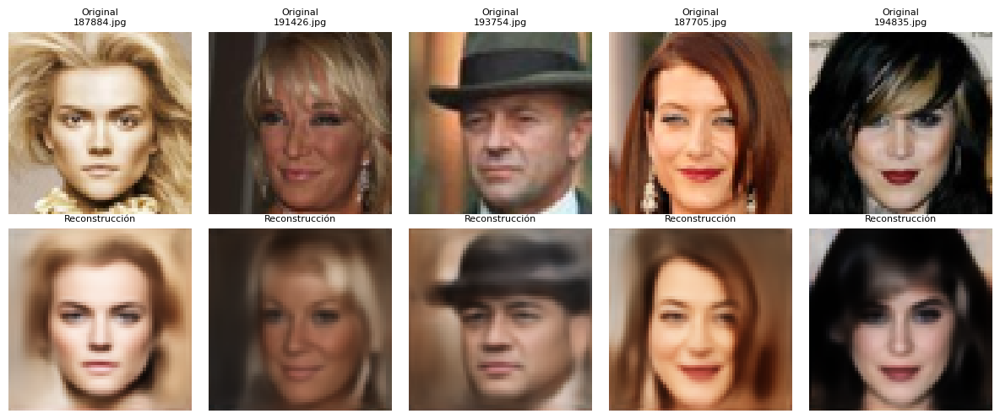

In [ ]:
test_indices = sample_rng.choice(len(x_test), size=5, replace=False)
test_reconstructions = autoencoder.predict(x_test[test_indices], verbose=0)
comparison = np.concatenate([x_test[test_indices], test_reconstructions], axis=0)
titles = [f"Original\n{ids_test[i]}" for i in test_indices] + ["Reconstrucción"] * len(test_indices)
show_images(comparison, titles, cols=5, figsize=(12, 5))

Mejor época según val_loss: 60


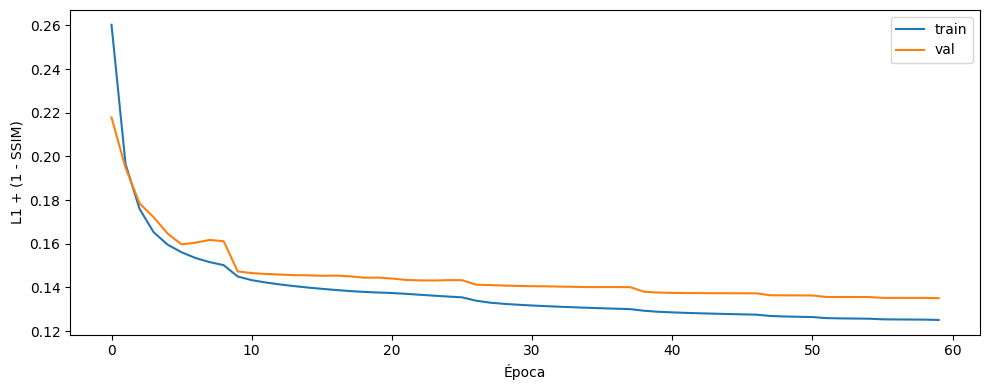

In [ ]:
if hasattr(history_ae, "history") and "val_loss" in history_ae.history:
    best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
    print(f"Mejor época según val_loss: {best_epoch}")
    plt.figure(figsize=(10, 4))
    plt.plot(history_ae.history["loss"], label="train")
    plt.plot(history_ae.history["val_loss"], label="val")
    plt.xlabel("Época")
    plt.ylabel("L1 + (1 - SSIM)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# Preparamos el FID: comparamos distribuciones y no imágenes individuales.
# Usamos test para mantener la evaluación separada del entrenamiento.
# El FID compara distribuciones de imágenes; por eso se usa un conjunto de test.

FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_REAL_SAMPLES = min(1000, len(x_test))
FID_BATCH_SIZE = 32


# Convertimos al formato y rango que espera TorchMetrics.
def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se esperaban imágenes con forma (N, H, W, 1|3); recibidas {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    return float(fid.compute().item())

In [ ]:
fid_reconstruction_images = x_test[:FID_REAL_SAMPLES]
fid_reconstruction_reference = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]
reconstructed_test_images = autoencoder.predict(
    fid_reconstruction_images,
    batch_size=FID_BATCH_SIZE,
    verbose=0,
)
reconstruction_fid = calculate_fid(
    reconstructed_test_images,
    fid_reconstruction_reference,
)
print(f"FID de reconstrucciones ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

FID de reconstrucciones (1000 imágenes): 72.9363


---

## **7. FID y morphing mediante interpolación en el espacio latente**

El **Fréchet Inception Distance (FID)** compara dos distribuciones de imágenes a partir de características extraídas por una red Inception. Resume la distancia entre sus medias y covarianzas mediante la distancia de Fréchet: un FID más bajo indica que las imágenes generadas se parecen más, en distribución, a las imágenes reales de referencia. Un FID alto significa diferencias de calidad, variedad o contenido; no debe interpretarse como una medida de identidad de una imagen concreta ni como prueba suficiente de un morphing correcto. Aquí lo calculamos con imágenes `test` no usadas para entrenar, para comparar reconstrucciones y referencias reales bajo el mismo protocolo. 

Normalmente, el techo de nuestras reconstrucciones va a ser el FID más alto al que vamos a poder aspirar al hacer morphing con esta arquitectura. Una imagen aleatoria con esta forma de cálculo del FID daría un valor de unos 500 aproximadamente.

Para el morphing elegimos dos imágenes del conjunto `test`, codificamos sus latentes $z_A$ y $z_B$ y calculamos

$$z_\alpha = (1-\alpha) z_A + \alpha z_B, \qquad \alpha \in [0,1].$$

El decoder transforma cada $z_\alpha$ en una imagen. Los extremos se comparan con las imágenes originales para distinguir el efecto de la reconstrucción del efecto de la interpolación. Al aumentar el número de valores de $\alpha$ obtenemos más fotogramas y una transición más fluida en el GIF.

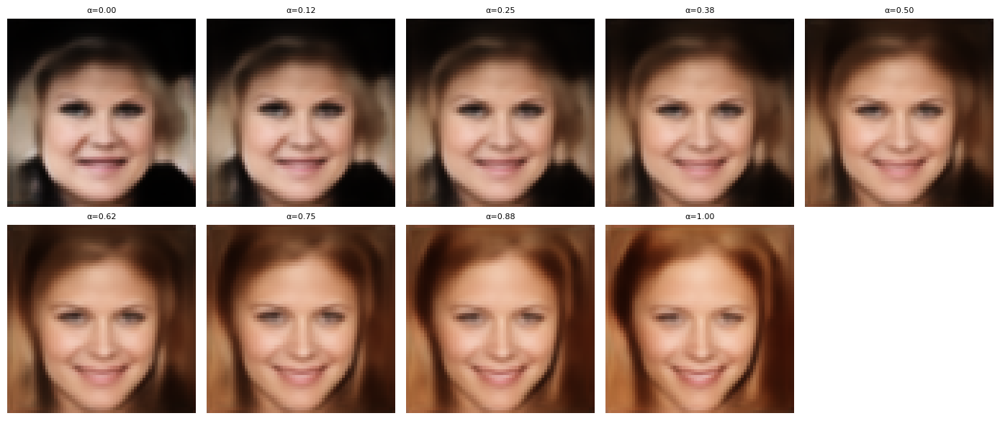

A: 182638.jpg | B: 182640.jpg


In [ ]:
def morph_images(image_a, image_b, steps=9):
    if image_a.shape != image_b.shape:
        raise ValueError(f"Las imágenes deben tener la misma forma; recibidas {image_a.shape} y {image_b.shape}")
    # Codificamos ambos extremos y recorremos una línea recta entre sus latentes.
    z_a = encoder_ae.predict(image_a[None, ...], verbose=0)[0]
    z_b = encoder_ae.predict(image_b[None, ...], verbose=0)[0]
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)
    latent_path = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b
    return alphas, decoder_ae.predict(latent_path, verbose=0)

morph_a_index, morph_b_index = 0, 1
alphas, morph_sequence = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9)
show_images(
    morph_sequence,
    [f"α={alpha:.2f}" for alpha in alphas],
    cols=5,
    figsize=(14, 6),
)
print(f"A: {ids_test[morph_a_index]} | B: {ids_test[morph_b_index]}")

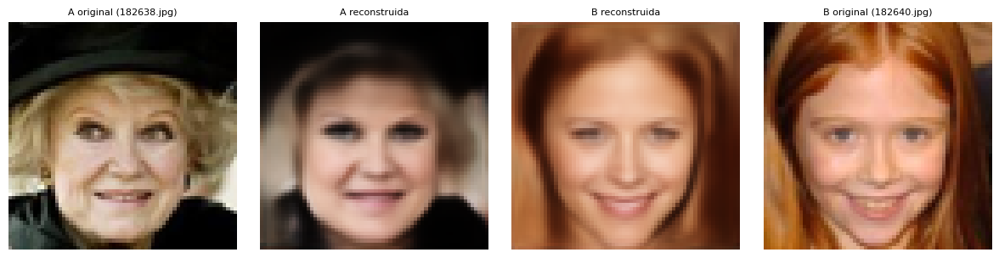

In [ ]:
# Comparación de extremos: original frente a reconstrucción usada en la interpolación.
endpoints = np.stack([
    x_test[morph_a_index], morph_sequence[0],
    morph_sequence[-1], x_test[morph_b_index],
])
show_images(
    endpoints,
    [f"A original ({ids_test[morph_a_index]})", "A reconstruida", "B reconstruida", f"B original ({ids_test[morph_b_index]})"],
    cols=4,
    figsize=(12, 3),
)

---

## **8. Secuencia visual y GIF del morphing**

Finalmente repetimos la interpolación con muchos valores de $\alpha$ y guardamos los fotogramas como un GIF. La animación nos permite evaluar visualmente si los rasgos cambian de manera gradual, sin saltos ni *ghosting*, complementando la evaluación numérica del FID.

In [ ]:
GIF_PATH = PROCESSED_DIR.parent.parent / "gif" / "fusion_ae1_morphing1.gif"
N_FRAMES = 80
FRAME_MS = 50

z_a = encoder_ae.predict(
    x_test[morph_a_index][None, ...],
    verbose=0,
)[0]
z_b = encoder_ae.predict(
    x_test[morph_b_index][None, ...],
    verbose=0,
)[0] 

# Generamos muchos puntos para que la animación resulte visualmente continua.
alphas = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)
z_frames = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b

decoded = decoder_ae.predict(z_frames, verbose=0)

GIF guardado en '/Users/dani22/Desktop/ProyectoCD/morphing/gif/fusion_ae1_morphing1.gif' | 80 fotogramas


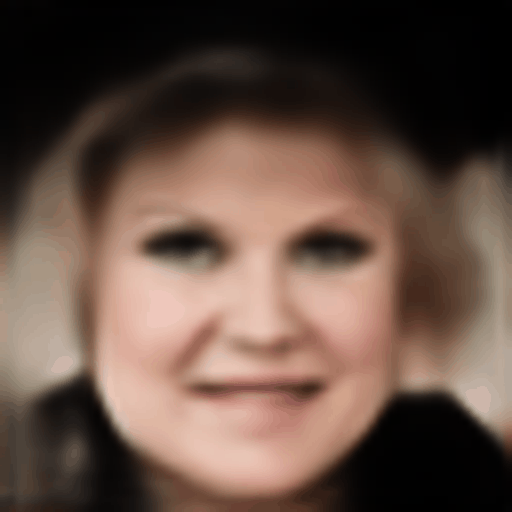

In [ ]:
frames = [
    Image.fromarray((np.clip(image, 0, 1) * 255).astype(np.uint8))
    .resize((512, 512), Image.Resampling.BICUBIC)
    for image in decoded
]

gif_path = Path(GIF_PATH).resolve()
gif_path.parent.mkdir(parents=True, exist_ok=True)
if not frames:
    raise RuntimeError("No se generaron fotogramas para el GIF")

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=FRAME_MS,
    loop=0,
)

print(f"GIF guardado en '{gif_path}' | {len(frames)} fotogramas")
display(IPyImage(filename=str(gif_path)))

---

## **9. Decisiones de diseño y futuras mejoras**

Las decisiones de este primer autoencoder buscan equilibrar calidad, estabilidad y coste computacional. No pretendemos construir la arquitectura óptima, sino construir una base que podamos entender y comparar en los siguientes experimentos. Algunas de las decisiones de diseño que hemos tomado en este notebook son:

- **Reducción mediante convoluciones con `stride=2`, sin `MaxPooling`:** usamos convoluciones que reducen la resolución y aprenden simultáneamente los filtros necesarios para representar los rasgos faciales. Al no separar la reducción espacial de la extracción de características, mantenemos más control sobre qué información se conserva y dejamos que el modelo aprenda la transformación en lugar de imponer una operación fija de máximo.

- **Convolución y `UpSampling` en el decoder, en lugar de `Conv2DTranspose`:** primero aumentamos la resolución mediante y después aplicamos una convolución. Esta combinación evita los llamados patrones de cuadrícula, que pueden aparecer con algunas configuraciones de convoluciones transpuestas y hace más explícita la separación entre recuperar resolución y refinar detalles.

- **Espacio latente de 128 dimensiones:** elegimos `LATENT_DIM = 128` como balanza entre compresión y capacidad descriptiva. Un espacio más pequeño pierde mucha identidad, textura y geometría facial; uno mayor podría reconstruir mejor, pero reduciría la presión para aprender una representación compacta y aumentaría el coste.

Encontrar el mejor modelo posible mediante una búsqueda exhaustiva de arquitecturas, resoluciones, dimensiones latentes, pérdidas e hiperparámetros es inviable con nuestra capacidad de cómputo actual. Por eso nuestro objetivo no es declarar que este modelo sea el óptimo, sino **entender al máximo cómo funciona cada decisión y reconocer qué alternativas deberían funcionar mejor** si pudiéramos entrenar modelos más grandes, con caras de mayor resolución y autoencoders de mayor capacidad.

Como futuras mejoras, la primera que realizaremos será comprobar si un aumento del espacio latente mejora la calidad de la reconstrucción. Esto se desarrolla en el siguiente notebook, **`AE_complex1_latent.ipynb`**.